# IND320 Part 2 — APIs, Cassandra, Spark and MongoDB

This notebook continues the Part 1 reservoir dashboard and documents the data work behind the Streamlit app:

1. **NVE Magasinstatistikk API** replaces the Part 1 CSV file. The Part 1 plots are recreated from the API.
2. **ENTSO-E Transparency Platform API**: hourly cross-border physical flows to and from Norway for two years.
3. **Cassandra + Spark** (local): the raw ENTSO-E data are written to Cassandra with Spark, and Spark extracts the relevant columns.
4. **MongoDB Atlas** (remote): the Spark-prepared data are stored in MongoDB, where the Streamlit app reads them.

```
NVE API ───────────────────────────────────────────────▶ Streamlit (pages 1–3)
ENTSO-E API ─▶ pandas ─▶ Spark ─▶ Cassandra ─▶ Spark ─▶ MongoDB ─▶ Streamlit (page 4)
```

## Project links

- Public GitHub repository: https://github.com/yaksh-git/ind320-dashboard-basics-yaksh-git
  (Part 2 work on the branch [`codex/ind320-part2`](https://github.com/yaksh-git/ind320-dashboard-basics-yaksh-git/tree/codex/ind320-part2))
- Streamlit app: https://ind320-dashboard-basics-yaksh-git.streamlit.app/
- The AI-usage statement and the work log are in sections 8 and 9 at the end.

## 1. Setup

The notebook lives in `notebooks/` and runs with the project's Python 3.12 environment
(`notebooks/requirements.txt`). Paths are resolved from the repository root, so the notebook works whether Jupyter
starts in `notebooks/` or in the root. Secrets are read from `.streamlit/secrets.toml`, which is listed in
`.gitignore` and therefore never pushed to GitHub. The file has this shape:

```toml
[mongo]
uri = "mongodb+srv://<user>:<password>@<cluster>.mongodb.net/?retryWrites=true&w=majority"
database = "ind320"

[entsoe]
token = "<ENTSO-E security token>"
```

The Streamlit app reads the same `[mongo]` section through `st.secrets`; on Streamlit Community Cloud
the section is pasted into the app's *Secrets* settings instead.

In [1]:
# Standard library
import os
import subprocess
import sys
import tomllib
import xml.etree.ElementTree as ET
from pathlib import Path

# The repository root holds app.py; Jupyter usually starts in the notebook's own folder (notebooks/).
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

# Matplotlib needs a writable cache folder; set it before Matplotlib is imported (as in Part 1).
mpl_cache = ROOT / '.matplotlib'
mpl_cache.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(mpl_cache.resolve())

# Third-party packages
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
import requests
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook', palette='deep')

# Downloaded API data are cached here (ignored by Git) so re-runs need fewer slow requests.
CACHE_DIR = ROOT / 'data' / 'cache'
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Read secrets from the local, Git-ignored TOML file. Only section names are printed, never values.
with open(ROOT / '.streamlit' / 'secrets.toml', 'rb') as file:
    secrets = tomllib.load(file)
print('Python', sys.version.split()[0], '| pandas', pd.__version__)
print('Secret sections found:', ', '.join(secrets))

Python 3.12.15 | pandas 2.3.3
Secret sections found: mongo, entsoe


## 2. NVE Magasinstatistikk API

The [Swagger page](https://biapi.nve.no/magasinstatistikk/swagger/index.html) lists four GET endpoints.
None of them needs a key, and none of them takes parameters:

| Endpoint | Content |
|---|---|
| `HentOffentligData` | All weekly reports since 1995 for every area (the same fields as the Part 1 CSV) |
| `HentOffentligDataSisteUke` | Only the latest week |
| `HentOffentligDataMinMaxMedian` | Minimum, median and maximum per ISO week over the last 20 years |
| `HentOmråder` | Names and descriptions of the areas |

### 2.1 Which areas of Norway does the API cover?

In [2]:
NVE_URL = 'https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk'


def get_nve(endpoint):
    """Call one NVE endpoint and return the decoded JSON body."""
    response = requests.get(f'{NVE_URL}/{endpoint}', headers={'Accept': 'application/json'}, timeout=60)
    response.raise_for_status()  # Stop with a clear error on HTTP 4xx/5xx.
    return response.json()


# HentOmråder returns one object with three lists: land (country), elspot (price areas) and vassdrag.
area_groups = get_nve('HentOmråder')[0]
areas = pd.DataFrame([area for group in area_groups.values() for area in group])
areas = areas.rename(columns={'navn': 'name', 'beskrivelse': 'description',
                              'omrType': 'area_type', 'omrnr': 'area_number'})
pd.set_option('display.max_colwidth', 120)
display(areas[['area_type', 'area_number', 'name', 'description']])

,area_type,area_number,name,description
0,NO,0,Norge,Hele landet
1,EL,1,NO 1,Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligg...
2,EL,2,NO 2,"Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland."
3,EL,3,NO 3,"Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Mø..."
4,EL,4,NO 4,Nord-Norge. Omfatter resten av Trøndelag og Nord-Norge.
5,EL,5,NO 5,"Vest-Norge. Omfatter midtre del av Vestland opp til Sognefjorden og Indre Sogn, og vestlig del av Buskerud."
6,VASS,1,VASS1,"Sørøst-Norge. Østlandet, Agder og deler av Rogaland."
7,VASS,2,VASS2,Vest-Norge. Resten av Rogaland og Vestland.
8,VASS,3,VASS3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørlige Nordland"
9,VASS,4,VASS4,Nord-Norge. Resten av Nordland og nordover.


The API uses three kinds of area (`omrType`):

- **NO 0** — Norway as a whole.
- **EL 1–5** — the five electricity price areas (elspot areas NO1–NO5).
- **VASS 1–4** — watercourse regions. The data check below shows whether all of them have measurements.

### 2.2 Download all weekly reports

`HentOffentligData` returns the full history (about 4 MB of JSON) in one request. The field names are identical
to the Part 1 CSV, so the Part 1 translation to English can be reused unchanged.

In [3]:
# Translate the Norwegian field names once; later cells use the English names (as in Part 1).
column_names = {
    'dato_Id': 'date',
    'omrType': 'area_type',
    'omrnr': 'area_number',
    'iso_aar': 'iso_year',
    'iso_uke': 'iso_week',
    'fyllingsgrad': 'fill_level',
    'kapasitet_TWh': 'capacity_twh',
    'fylling_TWh': 'stored_energy_twh',
    'neste_Publiseringsdato': 'next_publication_date',
    'fyllingsgrad_forrige_uke': 'previous_week_fill_level',
    'endring_fyllingsgrad': 'fill_level_change',
}
data = pd.DataFrame(get_nve('HentOffentligData')).rename(columns=column_names)

# Part 1 lesson: give date formats explicitly instead of letting pandas guess.
data['date'] = pd.to_datetime(data['date'], format='%Y-%m-%d')
data = data.sort_values(['date', 'area_type', 'area_number']).reset_index(drop=True)
national = data.loc[(data['area_type'] == 'NO') & (data['area_number'] == 0)].copy()

print(f'{len(data):,} rows, {len(data.columns)} columns')
print(f'{data.date.min():%Y-%m-%d} to {data.date.max():%Y-%m-%d}')
# Which area types and numbers actually have measurements?
display(data.groupby('area_type')['area_number'].unique().to_frame('area numbers with data'))

14,922 rows, 11 columns
1995-01-08 to 2026-10-11


,area numbers with data
area_type,
EL,"[1, 2, 3, 4, 5]"
NO,[0]
VASS,"[1, 2, 3]"


### 2.3 The time columns

In Part 1 the time columns needed care: `neste_Publiseringsdato` uses year `0001` when no date was supplied, which
is outside the range pandas can represent. The checks below confirm how the API's time fields fit together.

In [4]:
# 1) dato_Id: which weekday is it? (0 = Monday ... 6 = Sunday)
print('Weekdays of dato_Id:', data['date'].dt.dayofweek.value_counts().to_dict())

# 2) Do iso_aar / iso_uke agree with the ISO calendar week of dato_Id?
iso = data['date'].dt.isocalendar()
print('ISO year and week match dato_Id:',
      bool(((iso['year'] == data['iso_year']) & (iso['week'] == data['iso_week'])).all()))

# 3) next_publication_date: parse with an explicit format; year 0001 becomes NaT (no date supplied).
next_date = pd.to_datetime(data['next_publication_date'], format='%Y-%m-%dT%H:%M:%S', errors='coerce')
print(f'Rows without a publication date (0001): {next_date.isna().sum():,} of {len(data):,}')
print('Weekday and time of supplied publication dates:',
      next_date.dropna().dt.strftime('%A %H:%M').value_counts().head(3).to_dict())

# 4) Areas listed by HentOmråder that never appear in the data.
listed = set(zip(areas['area_type'], areas['area_number']))
measured = set(zip(data['area_type'], data['area_number']))
print('Listed areas without data:', sorted(listed - measured))

Weekdays of dato_Id: {6: 14922}
ISO year and week match dato_Id: True
Rows without a publication date (0001): 11,322 of 14,922
Weekday and time of supplied publication dates: {'Wednesday 13:00': 3555, 'Thursday 13:00': 36, 'Friday 13:00': 9}
Listed areas without data: [('VASS', 4)]


**Findings.** `dato_Id` is always a Sunday: the last day of the ISO week that the measurement describes, and the
ISO year/week fields agree with it. Publication dates are mostly missing (`0001`) for older rows; when present,
they point to NVE's weekly release, normally Wednesday at 13:00 (Thursday or Friday in some holiday weeks). The API therefore covers **Norway (NO 0), the five price
areas (EL 1–5) and three watercourse regions (VASS 1–3)**; VASS 4 (Nord-Norge) is defined in `HentOmråder` but has
no measurements.

### 2.4 Recreate the Part 1 plots from the API

The cells below are the Part 1 plots, now fed by the API instead of `reservoirs.csv`. As in Part 1, time series
use the Norway total (`NO`, area `0`) so that each line follows one consistent area.

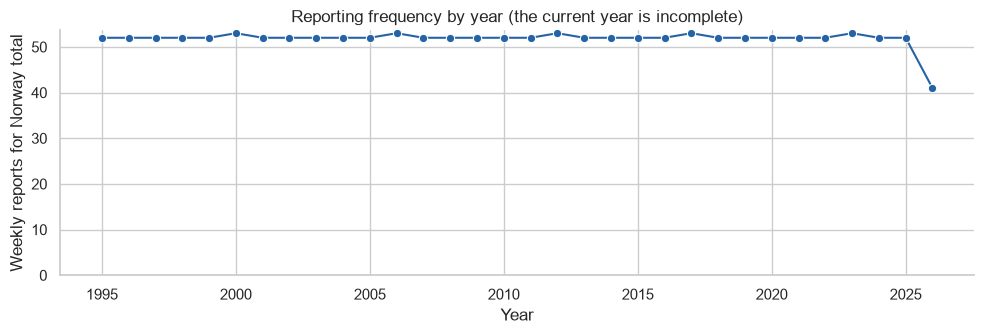

In [5]:
# A date cannot be plotted against itself; count reports in each year.
annual = national.groupby(national['date'].dt.year).size().rename('reports')
annual = annual.rename_axis('year').reset_index()
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.lineplot(data=annual, x='year', y='reports', marker='o', color='#2563a6', errorbar=None, ax=ax)
ax.set(title='Reporting frequency by year (the current year is incomplete)', xlabel='Year',
       ylabel='Weekly reports for Norway total')
ax.set_ylim(bottom=0)
sns.despine()
fig.tight_layout(); plt.show()

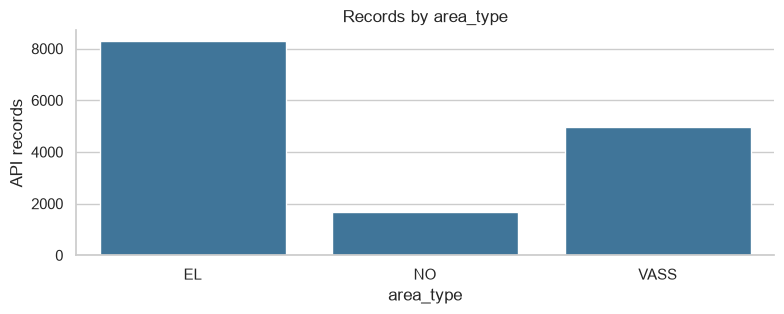

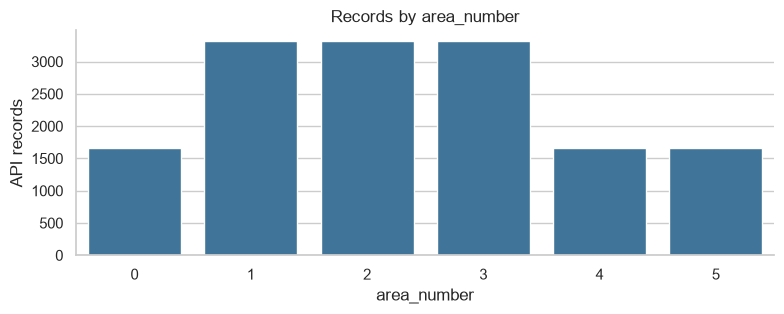

In [6]:
# Area fields are categories, so count their occurrences in all rows.
for column in ['area_type', 'area_number']:
    fig, ax = plt.subplots(figsize=(8, 3.3))
    sns.countplot(data=data, x=column, color='#3178a8', ax=ax)
    ax.set(title=f'Records by {column}', xlabel=column, ylabel='API records')
    sns.despine()
    fig.tight_layout(); plt.show()

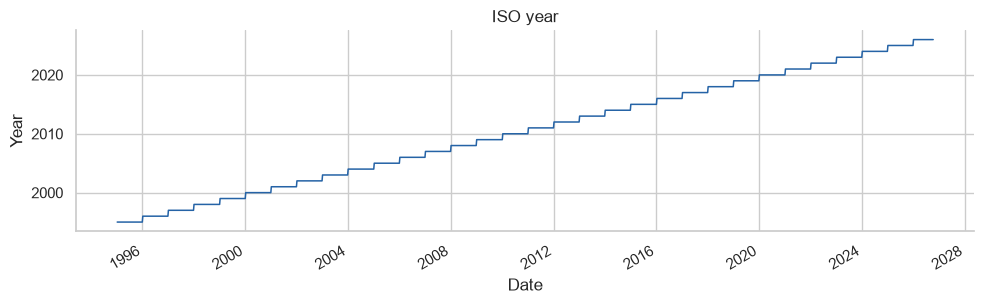

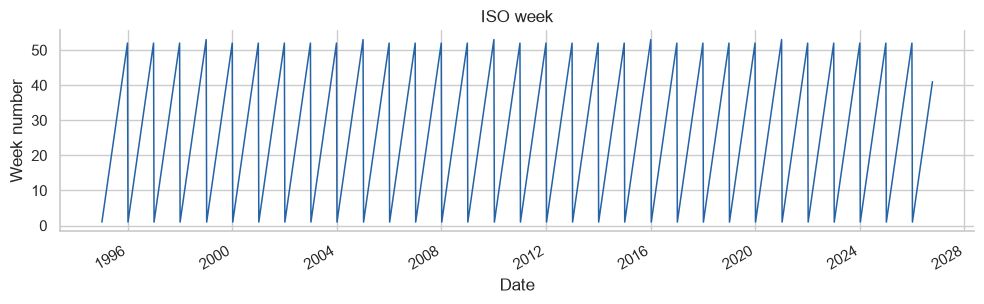

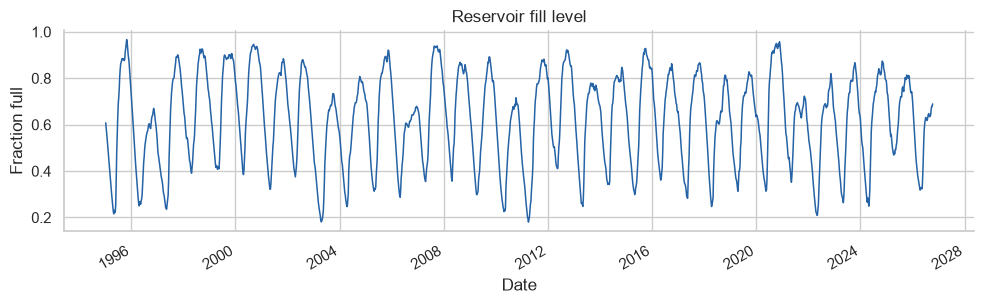

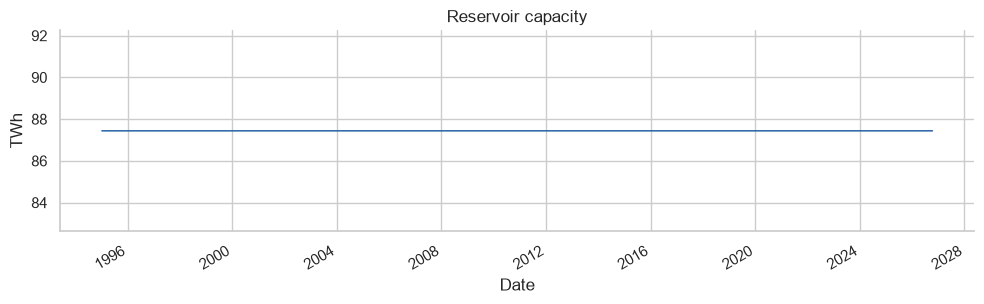

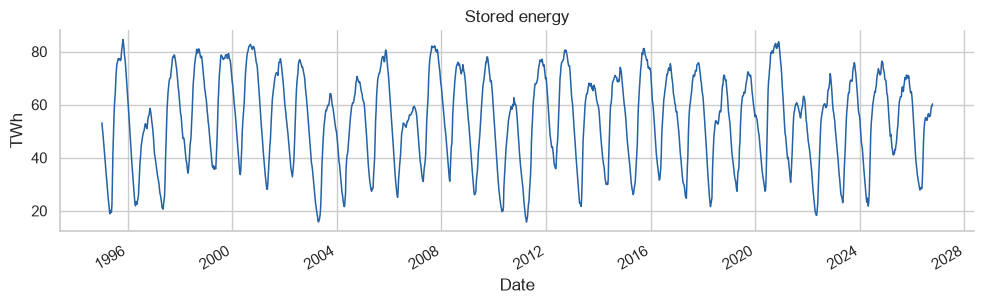

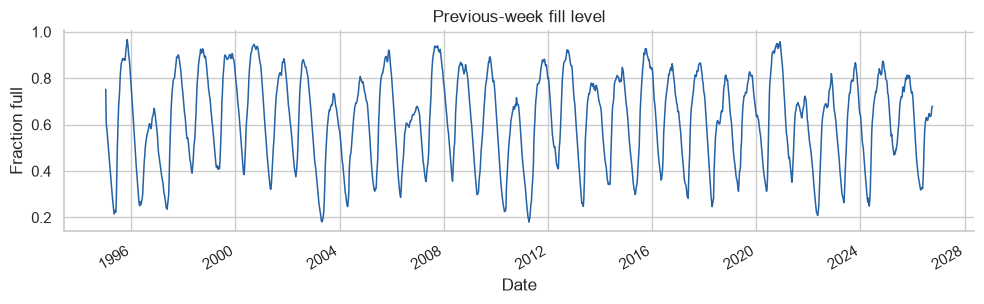

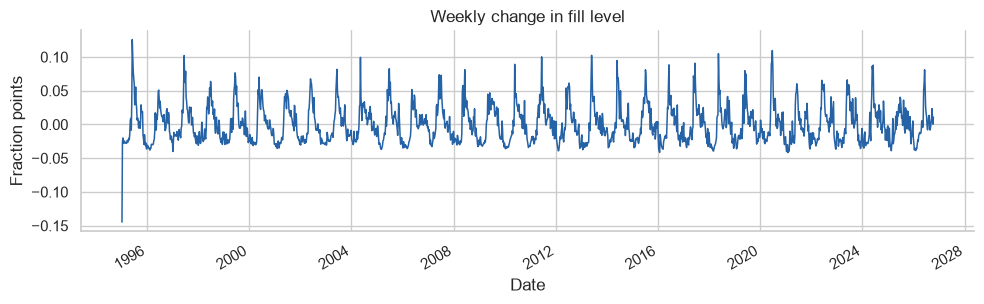

In [7]:
# Each numeric field is a time series for one coherent geographic area (Norway total).
numeric_columns = ['iso_year', 'iso_week', 'fill_level', 'capacity_twh',
                   'stored_energy_twh', 'previous_week_fill_level', 'fill_level_change']
labels = {'iso_year': ('ISO year', 'Year'),
          'iso_week': ('ISO week', 'Week number'),
          'fill_level': ('Reservoir fill level', 'Fraction full'),
          'capacity_twh': ('Reservoir capacity', 'TWh'),
          'stored_energy_twh': ('Stored energy', 'TWh'),
          'previous_week_fill_level': ('Previous-week fill level', 'Fraction full'),
          'fill_level_change': ('Weekly change in fill level', 'Fraction points')}
for column in numeric_columns:
    fig, ax = plt.subplots(figsize=(10, 3.2))
    sns.lineplot(data=national, x='date', y=column, estimator=None,
                 errorbar=None, color='#2563a6', linewidth=1.1, ax=ax)
    ax.set(title=labels[column][0], xlabel='Date', ylabel=labels[column][1])
    sns.despine()
    fig.autofmt_xdate()
    fig.tight_layout(); plt.show()

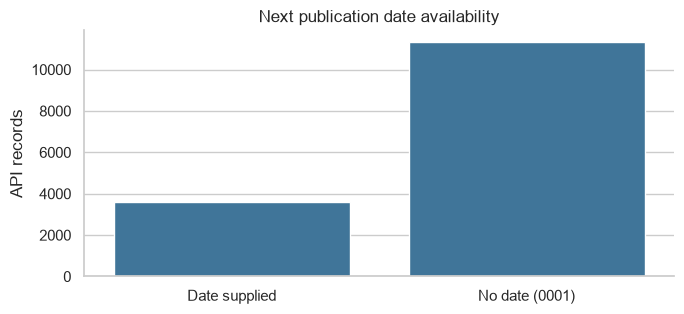

In [8]:
# Year 0001 is outside pandas' datetime range and means no usable date (parsed in section 2.3).
publication_counts = pd.DataFrame({'status': ['Date supplied', 'No date (0001)'],
                                   'rows': [next_date.notna().sum(), next_date.isna().sum()]})
fig, ax = plt.subplots(figsize=(7, 3.3))
sns.barplot(data=publication_counts, x='status', y='rows', color='#3178a8', errorbar=None, ax=ax)
ax.set(title='Next publication date availability', xlabel='', ylabel='API records')
sns.despine()
fig.tight_layout(); plt.show()

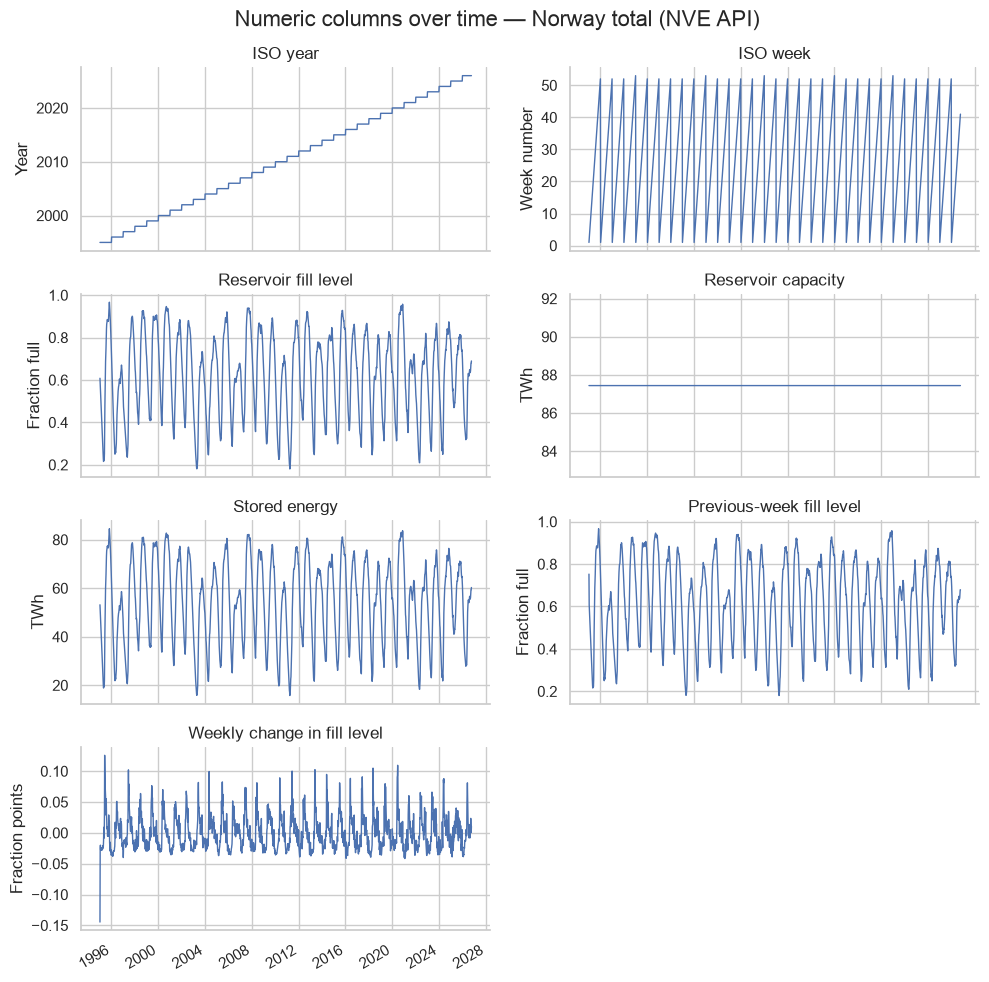

In [9]:
# Small multiples show all numeric fields without mixing their units.
fig, axes = plt.subplots(4, 2, figsize=(10, 10), sharex=True)
for ax, column in zip(axes.flat, numeric_columns):
    sns.lineplot(data=national, x='date', y=column, estimator=None, errorbar=None, linewidth=1, ax=ax)
    ax.set(title=labels[column][0], xlabel='', ylabel=labels[column][1])
    sns.despine(ax=ax)
axes.flat[-1].axis('off')
fig.suptitle('Numeric columns over time — Norway total (NVE API)', fontsize=16)
fig.autofmt_xdate()
fig.tight_layout(); plt.show()

### 2.5 Fill level for each area type (as on the app's *Data table* and *Data plot* pages)

In the app, the user picks a download interval and an area type, and the pages draw one line per area.
The same idea for the last five years:

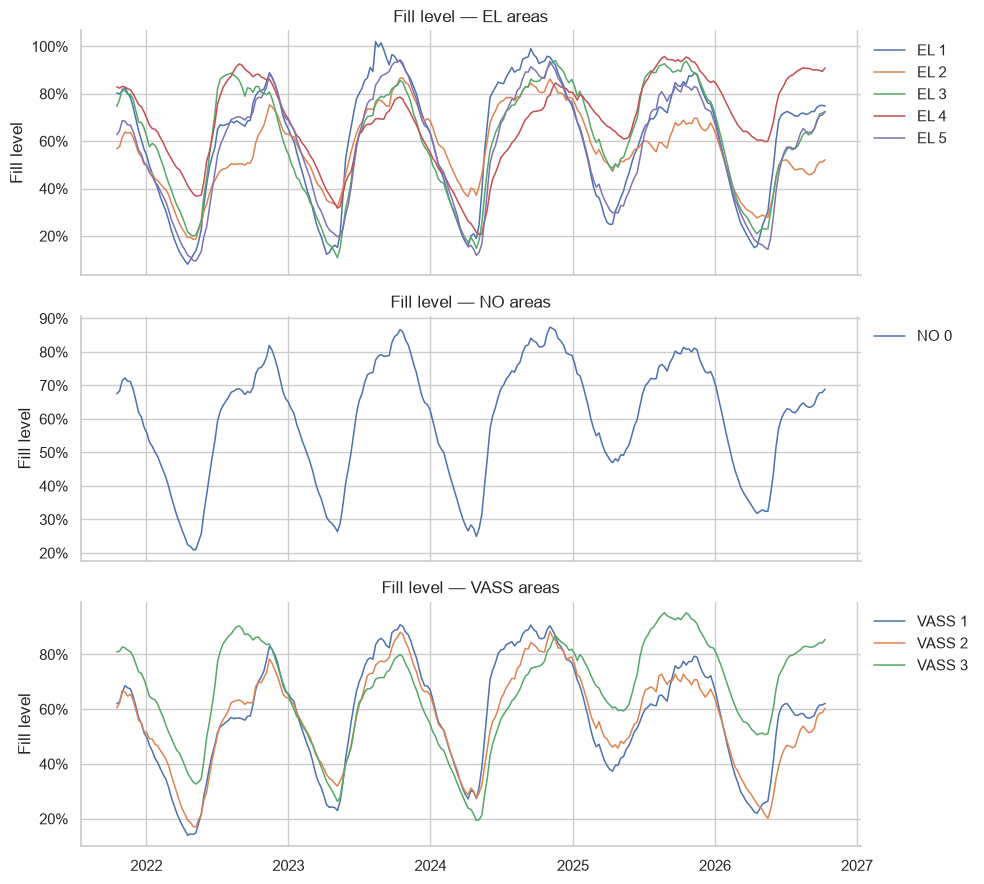

In [10]:
# One panel per area type (EL, NO, VASS) and one line per area number.
recent = data.loc[data['date'] >= data['date'].max() - pd.DateOffset(years=5)].copy()
recent['area'] = recent['area_type'] + ' ' + recent['area_number'].astype(str)
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, area_type in zip(axes, ['EL', 'NO', 'VASS']):
    sns.lineplot(data=recent.loc[recent['area_type'] == area_type], x='date', y='fill_level',
                 hue='area', estimator=None, errorbar=None, linewidth=1.1, ax=ax)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set(title=f'Fill level — {area_type} areas', xlabel='', ylabel='Fill level')
    ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False)
    sns.despine(ax=ax)
fig.tight_layout(); plt.show()

## 3. Local database: Cassandra and Spark

Cassandra runs locally in Docker, as described in the course book. The first time:

```bash
docker run --name my_cassandra -p 9042:9042 -d cassandra:latest
```

and later `docker start my_cassandra` (or press *Start* in Docker Desktop). Cassandra needs about a minute
after start-up before it accepts connections.

### 3.1 Keyspace and tables with the Python driver

In [11]:
from cassandra.cluster import Cluster

# Connect to the local Cassandra node published by Docker on port 9042.
cluster = Cluster(['localhost'], port=9042)
session = cluster.connect()
print('Connected to Cassandra', session.execute('SELECT release_version FROM system.local').one()[0])

# A keyspace is Cassandra's "database". One local node needs only one copy of each row.
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")
session.set_keyspace('ind320')

# Small table used only to test the Spark-Cassandra connection below.
session.execute('CREATE TABLE IF NOT EXISTS connection_test (id int PRIMARY KEY, note text)')

# Raw ENTSO-E flows. The partition key (link, direction) keeps one series together;
# time is the clustering column, so rows in a partition are stored in time order.
# Writing the same (link, direction, time) again overwrites the row, so re-runs create no duplicates.
session.execute("""
    CREATE TABLE IF NOT EXISTS physical_flows (
        link text, direction text, time timestamp,
        neighbour text, from_area text, to_area text,
        resolution text, flow_mw double, energy_mwh double,
        PRIMARY KEY ((link, direction), time)
    ) WITH CLUSTERING ORDER BY (time ASC)
""")
print('Tables in ind320:', [row.table_name for row in session.execute(
    "SELECT table_name FROM system_schema.tables WHERE keyspace_name = 'ind320'")])

Connected to Cassandra 5.0.9
Tables in ind320: ['connection_test', 'physical_flows']


### 3.2 Start Spark and test the Spark–Cassandra connection

PySpark needs Java (Java 17 here) and the DataStax Spark Cassandra Connector, which Spark downloads
automatically the first time from the `spark.jars.packages` setting. The versions follow the course book:
PySpark 3.5.1 with `spark-cassandra-connector_2.12:3.5.1`.

In [12]:
# PySpark 3.5 still imports 'distutils', which Python 3.12 removed. Importing setuptools
# first provides a replacement (the course book's reason for installing setuptools).
import setuptools  # noqa: F401
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Point Spark to Java 17 (macOS helper) and to this notebook's Python environment.
if 'JAVA_HOME' not in os.environ and sys.platform == 'darwin':
    os.environ['JAVA_HOME'] = subprocess.check_output(['/usr/libexec/java_home', '-v', '17'], text=True).strip()
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
os.environ.setdefault('SPARK_LOCAL_IP', '127.0.0.1')  # Spark runs on this computer only

# Expected output: Spark lists the connector packages it resolves (downloaded the first time only)
# and a few start-up warnings, as the course book notes. The last line confirms the session.
spark = (SparkSession.builder.appName('IND320-Part2')
         # Connector that lets Spark read and write Cassandra tables.
         .config('spark.jars.packages', 'com.datastax.spark:spark-cassandra-connector_2.12:3.5.1')
         .config('spark.cassandra.connection.host', 'localhost')
         .config('spark.cassandra.connection.port', '9042')
         .config('spark.sql.extensions', 'com.datastax.spark.connector.CassandraSparkExtensions')
         # Keep all timestamps in UTC inside Spark; local time is added explicitly later.
         .config('spark.sql.session.timeZone', 'UTC')
         # Apache Arrow makes pandas <-> Spark conversion much faster for large tables.
         .config('spark.sql.execution.arrow.pyspark.enabled', 'true')
         .config('spark.driver.memory', '4g')
         .config('spark.ui.showConsoleProgress', 'false')  # no progress bars in the output
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')  # Hide routine INFO/WARN messages.
print('Spark', spark.version, '| Java', os.environ.get('JAVA_HOME', 'from PATH'))

:: loading settings :: url = jar:file:/Users/yaksh/Documents/Studying/ind320-dashboard-basics-yaksh-git/.venv/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /Users/yaksh/.ivy2/cache
The jars for the packages stored in: /Users/yaksh/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-5b3d8caa-cc6a-4308-a743-1c24305e3075;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams;1.0

26/10/18 15:23:20 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 3.5.1 | Java /Library/Java/JavaVirtualMachines/microsoft-17.jdk/Contents/Home


In [13]:
def write_cassandra(frame, table):
    """Append a Spark DataFrame to a table in the ind320 keyspace."""
    (frame.write.format('org.apache.spark.sql.cassandra')
     .options(table=table, keyspace='ind320').mode('append').save())


def read_cassandra(table):
    """Load a Cassandra table in the ind320 keyspace as a (lazy) Spark DataFrame."""
    return (spark.read.format('org.apache.spark.sql.cassandra')
            .options(table=table, keyspace='ind320').load())


# Round trip: pandas -> Spark -> Cassandra -> Spark.
test_rows = pd.DataFrame({'id': [1, 2], 'note': ['written by Spark', 'read back by Spark']})
write_cassandra(spark.createDataFrame(test_rows), 'connection_test')
read_cassandra('connection_test').orderBy('id').show()

+---+------------------+
| id|              note|
+---+------------------+
|  1|  written by Spark|
|  2|read back by Spark|
+---+------------------+



## 4. ENTSO-E: cross-border physical flows

The [ENTSO-E Transparency Platform](https://transparency.entsoe.eu/) collects European electricity market data.
After registering, I requested API access by e-mail and generated a security token under *My Account*.
The [API reference](https://documenter.getpostman.com/view/7009892/2s93JtP3F6) describes the data item
**12.1.G Cross-Border Physical Flows** (`documentType=A11`):

- `out_Domain` → `in_Domain`: the flow direction, given by EIC area codes. Each direction is requested
  separately, and the values are *not* netted.
- `periodStart`/`periodEnd` in UTC, format `yyyyMMddHHmm`. One request may cover **at most one year**.
- The response is XML: `TimeSeries` → `Period` (start, end, resolution) → numbered `Point`s with the power in MW.

### 4.1 Norway's cross-border links

Norway's interconnectors are defined between price areas. A **connection** below is Norway ↔ one neighbouring
country, and a **link** is one price-area pair on that connection (Sweden has four).

In [14]:
# EIC codes identify bidding zones (price areas) in the ENTSO-E API.
EIC = {
    'NO1': '10YNO-1--------2', 'NO2': '10YNO-2--------T', 'NO3': '10YNO-3--------J', 'NO4': '10YNO-4--------9',
    'SE1': '10Y1001A1001A44P', 'SE2': '10Y1001A1001A45N', 'SE3': '10Y1001A1001A46L',
    'FI': '10YFI-1--------U', 'DK1': '10YDK-1--------W',
    'DE': '10Y1001A1001A82H',  # The German-Luxembourg price area DE-LU (NordLink)
    'NL': '10YNL----------L',  # NorNed
    'GB': '10YGB----------A',  # North Sea Link
}
# (Norwegian area, foreign area, neighbouring country)
LINKS = pd.DataFrame([
    ('NO1', 'SE3', 'Sweden'), ('NO3', 'SE2', 'Sweden'), ('NO4', 'SE1', 'Sweden'), ('NO4', 'SE2', 'Sweden'),
    ('NO4', 'FI', 'Finland'), ('NO2', 'DK1', 'Denmark'), ('NO2', 'DE', 'Germany'),
    ('NO2', 'NL', 'Netherlands'), ('NO2', 'GB', 'Great Britain'),
], columns=['norway_area', 'foreign_area', 'neighbour'])
LINKS['link'] = LINKS['norway_area'] + '-' + LINKS['foreign_area']
LINKS

,norway_area,foreign_area,neighbour,link
0,NO1,SE3,Sweden,NO1-SE3
1,NO3,SE2,Sweden,NO3-SE2
2,NO4,SE1,Sweden,NO4-SE1
3,NO4,SE2,Sweden,NO4-SE2
4,NO4,FI,Finland,NO4-FI
5,NO2,DK1,Denmark,NO2-DK1
6,NO2,DE,Germany,NO2-DE
7,NO2,NL,Netherlands,NO2-NL
8,NO2,GB,Great Britain,NO2-GB


### 4.2 Request and parse one direction

Two details matter for correct numbers:

- **Resolution.** Some links report every 60 minutes, others every 15 minutes, and the resolution can change over
  time. Each point is therefore converted to energy: `MWh = MW × duration in hours`.
- **Curve type.** With curve type `A03`, ENTSO-E omits a point when the value is unchanged from the previous one.
  Missing positions are then filled forward. With `A01` every position is present.

The token is passed as a query parameter, so error messages are written by hand: the default `requests` error
would print the full URL, including the token.

In [15]:
from datetime import timedelta  # plain Python durations (pd.Timedelta warns with NumPy 2.5)

ENTSOE_URL = 'https://web-api.tp.entsoe.eu/api'
ENTSOE_TOKEN = secrets['entsoe']['token']
FLOW_COLUMNS = ['time', 'resolution', 'flow_mw', 'energy_mwh']
# ISO 8601 durations used by ENTSO-E for the time step of each Period.
RESOLUTIONS = {'PT15M': timedelta(minutes=15), 'PT30M': timedelta(minutes=30), 'PT60M': timedelta(hours=1)}


def parse_flow_document(xml_bytes):
    """Turn an ENTSO-E A11 XML document into a DataFrame with one row per time step."""
    root = ET.fromstring(xml_bytes)
    ns = {'ns': root.tag[1:].split('}')[0]}  # XML namespace, e.g. urn:iec62325...:publicationdocument:7:0
    frames = []
    for series in root.findall('ns:TimeSeries', ns):
        curve_type = series.findtext('ns:curveType', default='A01', namespaces=ns)
        for period in series.findall('ns:Period', ns):
            start = pd.Timestamp(period.findtext('ns:timeInterval/ns:start', namespaces=ns))
            end = pd.Timestamp(period.findtext('ns:timeInterval/ns:end', namespaces=ns))
            resolution = period.findtext('ns:resolution', namespaces=ns)  # e.g. 'PT60M' or 'PT15M'
            step = RESOLUTIONS[resolution]
            times = pd.date_range(start, end, freq=step, inclusive='left')  # one entry per position
            points = {int(point.findtext('ns:position', namespaces=ns)):
                      float(point.findtext('ns:quantity', namespaces=ns))
                      for point in period.findall('ns:Point', ns)}
            values = pd.Series(points, dtype=float).reindex(range(1, len(times) + 1))
            if curve_type == 'A03':
                values = values.ffill()  # A03 leaves out points that repeat the previous value
            frames.append(pd.DataFrame({'time': times, 'resolution': resolution,
                                        'flow_mw': values.to_numpy(),
                                        'energy_mwh': values.to_numpy() * (step / timedelta(hours=1))}))
    if not frames:
        return pd.DataFrame(columns=FLOW_COLUMNS)
    return pd.concat(frames, ignore_index=True).dropna(subset=['flow_mw'])


def fetch_flow(from_area, to_area, start, end):
    """Physical flow from from_area to to_area between two UTC timestamps (at most one year)."""
    params = {
        'securityToken': ENTSOE_TOKEN,
        'documentType': 'A11',           # A11 = cross-border physical flows
        'out_Domain': EIC[from_area],    # the flow leaves this area ...
        'in_Domain': EIC[to_area],       # ... and enters this one
        'periodStart': start.strftime('%Y%m%d%H%M'),
        'periodEnd': end.strftime('%Y%m%d%H%M'),
    }
    response = requests.get(ENTSOE_URL, params=params, timeout=180)
    if 'Acknowledgement_MarketDocument' in response.text:
        # ENTSO-E answers "no matching data" with an acknowledgement document instead of data.
        reason = ET.fromstring(response.content).findtext('.//{*}Reason/{*}text')
        print(f'  no data for {from_area} → {to_area} {start:%Y}: {reason}')
        return pd.DataFrame(columns=FLOW_COLUMNS)
    if response.status_code != 200:
        raise RuntimeError(f'ENTSO-E returned HTTP {response.status_code} for {from_area} → {to_area}')
    return parse_flow_document(response.content)


# Quick check on one day before downloading everything.
sample = fetch_flow('NO2', 'DE', pd.Timestamp('2025-01-01 00:00', tz='UTC'), pd.Timestamp('2025-01-02 00:00', tz='UTC'))
sample.head()

,time,resolution,flow_mw,energy_mwh
0,2025-01-01 00:00:00+00:00,PT15M,0.0,0.0
1,2025-01-01 00:15:00+00:00,PT15M,0.0,0.0
2,2025-01-01 00:30:00+00:00,PT15M,0.0,0.0
3,2025-01-01 00:45:00+00:00,PT15M,0.0,0.0
4,2025-01-01 01:00:00+00:00,PT15M,0.0,0.0


### 4.3 Download two years for all links and both directions

The period is the two most recent **complete calendar years, 2024 and 2025**, in Norwegian time. Complete years
make the yearly totals in the pie chart comparable, and both years have a January for the first-month plot.
Each year is a separate request (the one-year limit), so 9 links × 2 directions × 2 years = 36 requests.
The result is cached as a Parquet file; set `REFRESH = True` to download again.

In [16]:
START = pd.Timestamp('2024-01-01', tz='Europe/Oslo')  # inclusive
END = pd.Timestamp('2026-01-01', tz='Europe/Oslo')    # exclusive
REFRESH = False
raw_path = CACHE_DIR / f'entsoe_physical_flows_{START:%Y}_{END.year - 1}.parquet'

if raw_path.exists() and not REFRESH:
    raw = pd.read_parquet(raw_path)
    print(f'Loaded {len(raw):,} cached rows from {raw_path.relative_to(ROOT)}')
else:
    parts = []
    for link in LINKS.itertuples():
        # Export = out of Norway, import = into Norway.
        for direction, from_area, to_area in [('export', link.norway_area, link.foreign_area),
                                              ('import', link.foreign_area, link.norway_area)]:
            for year_start in pd.date_range(START, END, freq='YS', inclusive='left'):
                year_end = min(year_start + pd.DateOffset(years=1), END)
                part = fetch_flow(from_area, to_area, year_start.tz_convert('UTC'), year_end.tz_convert('UTC'))
                print(f'{from_area:>3} → {to_area:<3} {year_start:%Y}: {len(part):6,} rows')
                if not part.empty:
                    parts.append(part.assign(link=link.link, direction=direction, neighbour=link.neighbour,
                                             from_area=from_area, to_area=to_area))
    raw = pd.concat(parts, ignore_index=True)
    raw = raw.loc[(raw['time'] >= START) & (raw['time'] < END)]  # trim to the exact period
    raw.to_parquet(raw_path, index=False)
    print(f'Saved {len(raw):,} rows to {raw_path.relative_to(ROOT)}')

Loaded 788,928 cached rows from data/cache/entsoe_physical_flows_2024_2025.parquet


In [17]:
# What did we get? Rows, resolutions and total energy per link and direction.
summary = (raw.groupby(['neighbour', 'link', 'direction'])
           .agg(rows=('time', 'size'), resolutions=('resolution', lambda r: ', '.join(sorted(r.unique()))),
                first=('time', 'min'), last=('time', 'max'), twh=('energy_mwh', lambda e: e.sum() / 1e6))
           .round({'twh': 2}))
summary

rows   resolutions  \
neighbour     link    direction                        
Denmark       NO2-DK1 export     36837  PT15M, PT60M   
                      import     36837  PT15M, PT60M   
Finland       NO4-FI  export     63405  PT15M, PT60M   
                      import     63405  PT15M, PT60M   
Germany       NO2-DE  export     70176         PT15M   
                      import     70176         PT15M   
Great Britain NO2-GB  export     63405  PT15M, PT60M   
                      import     63405  PT15M, PT60M   
Netherlands   NO2-NL  export     63405  PT15M, PT60M   
                      import     63405  PT15M, PT60M   
Sweden        NO1-SE3 export     24309  PT15M, PT60M   
                      import     24309  PT15M, PT60M   
              NO3-SE2 export     24309  PT15M, PT60M   
                      import     24309  PT15M, PT60M   
              NO4-SE1 export     24309  PT15M, PT60M   
                      import     24309  PT15M, PT60M   
              NO4-SE2 export     24309  PT15M, PT60M   
                      import     24309  PT15M, PT60M   

                                                    first  \
neighbour     link    direction                             
Denmark       NO2-DK1 export    2023-12-31 23:00:00+00:00   
                      import    2023-12-31 23:00:00+00:00   
Finland       NO4-FI  export    2023-12-31 23:00:00+00:00   
                      import    2023-12-31 23:00:00+00:00   
Germany       NO2-DE  export    2023-12-31 23:00:00+00:00   
                      import    2023-12-31 23:00:00+00:00   
Great Britain NO2-GB  export    2023-12-31 23:00:00+00:00   
                      import    2023-12-31 23:00:00+00:00   
Netherlands   NO2-NL  export    2023-12-31 23:00:00+00:00   
                      import    2023-12-31 23:00:00+00:00   
Sweden        NO1-SE3 export    2023-12-31 23:00:00+00:00   
                      import    2023-12-31 23:00:00+00:00   
              NO3-SE2 export    2023-12-31 23:00:00+00:00   
                      import    2023-12-31 23:00:00+00:00   
              NO4-SE1 export    2023-12-31 23:00:00+00:00   
                      import    2023-12-31 23:00:00+00:00   
              NO4-SE2 export    2023-12-31 23:00:00+00:00   
                      import    2023-12-31 23:00:00+00:00   

                                                     last    twh  
neighbour     link    direction                                   
Denmark       NO2-DK1 export    2025-12-31 22:45:00+00:00  16.28  
                      import    2025-12-31 22:45:00+00:00   2.81  
Finland       NO4-FI  export    2025-12-31 22:45:00+00:00   0.53  
                      import    2025-12-31 22:45:00+00:00   0.08  
Germany       NO2-DE  export    2025-12-31 22:45:00+00:00  14.79  
                      import    2025-12-31 22:45:00+00:00   1.99  
Great Britain NO2-GB  export    2025-12-31 22:45:00+00:00  19.95  
                      import    2025-12-31 22:45:00+00:00   0.72  
Netherlands   NO2-NL  export    2025-12-31 22:45:00+00:00   6.29  
                      import    2025-12-31 22:45:00+00:00   1.01  
Sweden        NO1-SE3 export    2025-12-31 22:45:00+00:00   3.13  
                      import    2025-12-31 22:45:00+00:00  11.53  
              NO3-SE2 export    2025-12-31 22:45:00+00:00   1.57  
                      import    2025-12-31 22:45:00+00:00   4.31  
              NO4-SE1 export    2025-12-31 22:45:00+00:00   2.02  
                      import    2025-12-31 22:45:00+00:00   1.95  
              NO4-SE2 export    2025-12-31 22:45:00+00:00   0.92  
                      import    2025-12-31 22:45:00+00:00   0.73

In [18]:
# When did each link switch from hourly to 15-minute values (Norwegian time)?
first_15_min = (raw.loc[raw['resolution'] == 'PT15M'].groupby('link')['time'].min()
                .dt.tz_convert('Europe/Oslo').dt.strftime('%Y-%m-%d'))
display(first_15_min.rename('first 15-minute value').to_frame())

# NorNed (NO2-NL): days without any flow in either direction (cable out of service).
norned = raw.loc[raw['link'] == 'NO2-NL'].set_index('time')['energy_mwh'].resample('D').sum()
print(f'NorNed days with zero flow both ways: {(norned == 0).sum()} of {len(norned)}')

,first 15-minute value
link,
NO1-SE3,2025-09-29
NO2-DE,2024-01-01
NO2-DK1,2025-04-08
NO2-GB,2024-04-04
NO2-NL,2024-04-04
NO3-SE2,2025-09-29
NO4-FI,2024-04-04
NO4-SE1,2025-09-29
NO4-SE2,2025-09-29


NorNed days with zero flow both ways: 76 of 732


**Findings.** The time resolution is not the same for all links, and it changes during the period: NO2–DE reports
15-minute values throughout, while the other links switch from hourly to 15-minute values between April 2024 and
the end of September 2025 (the Swedish links last, in line with the Nordic move to 15-minute market time units).
Summing MW values directly would therefore count a 15-minute value as much as an hourly one; converting to MWh
first makes the periods comparable. NorNed (NO2–NL) has many days with no flow in either direction, which points
to periods when the cable was out of service.

### 4.4 Insert the raw data into Cassandra using Spark

Cassandra's `timestamp` type has no time zone; it stores UTC. The UTC times are therefore handed to Spark without
a time-zone label, and Spark's session time zone is UTC (section 3.2).

In [19]:
# Columns in the same order as the Cassandra table; times as UTC without a time-zone label.
cassandra_columns = ['link', 'direction', 'time', 'neighbour', 'from_area', 'to_area',
                     'resolution', 'flow_mw', 'energy_mwh']
raw_for_cassandra = raw[cassandra_columns].copy()
raw_for_cassandra['time'] = raw_for_cassandra['time'].dt.tz_convert('UTC').dt.tz_localize(None)

raw_spark = spark.createDataFrame(raw_for_cassandra)
raw_spark.printSchema()
write_cassandra(raw_spark, 'physical_flows')
print(f'Wrote {len(raw_for_cassandra):,} rows to Cassandra table ind320.physical_flows')

root
 |-- link: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- time: timestamp (nullable = true)
 |-- neighbour: string (nullable = true)
 |-- from_area: string (nullable = true)
 |-- to_area: string (nullable = true)
 |-- resolution: string (nullable = true)
 |-- flow_mw: double (nullable = true)
 |-- energy_mwh: double (nullable = true)



Wrote 788,928 rows to Cassandra table ind320.physical_flows


## 5. Extract the relevant columns from Cassandra with Spark

Spark reads the Cassandra table lazily: nothing is computed until a result is requested. The chain below

1. **selects** the columns needed by the plots and the app,
2. **aggregates** 15- and 60-minute values to one value per hour (sum of MWh, so mixed resolutions become comparable),
3. **adds** year and month in Norwegian local time, so that "January" starts at midnight in Oslo.

In [20]:
flows = read_cassandra('physical_flows')
print(f'Rows in Cassandra: {flows.count():,}')

hourly = (flows
          .select('neighbour', 'link', 'from_area', 'to_area', 'direction', 'time', 'energy_mwh')
          .withColumn('time', F.date_trunc('hour', 'time'))  # 15-minute values -> their hour
          .groupBy('neighbour', 'link', 'from_area', 'to_area', 'direction', 'time')
          .agg(F.sum('energy_mwh').alias('energy_mwh'))
          .withColumn('local_time', F.from_utc_timestamp('time', 'Europe/Oslo'))
          .withColumn('year', F.year('local_time'))
          .withColumn('month', F.month('local_time'))
          .drop('local_time')
          .orderBy('link', 'direction', 'time'))
hourly.printSchema()
hourly.show(5)

Rows in Cassandra: 788,928
root
 |-- neighbour: string (nullable = true)
 |-- link: string (nullable = false)
 |-- from_area: string (nullable = true)
 |-- to_area: string (nullable = true)
 |-- direction: string (nullable = false)
 |-- time: timestamp (nullable = true)
 |-- energy_mwh: double (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)



+---------+-------+---------+-------+---------+-------------------+----------+----+-----+
|neighbour|   link|from_area|to_area|direction|               time|energy_mwh|year|month|
+---------+-------+---------+-------+---------+-------------------+----------+----+-----+
|   Sweden|NO1-SE3|      NO1|    SE3|   export|2023-12-31 23:00:00|       0.0|2024|    1|
|   Sweden|NO1-SE3|      NO1|    SE3|   export|2024-01-01 00:00:00|       0.0|2024|    1|
|   Sweden|NO1-SE3|      NO1|    SE3|   export|2024-01-01 01:00:00|       0.0|2024|    1|
|   Sweden|NO1-SE3|      NO1|    SE3|   export|2024-01-01 02:00:00|       0.0|2024|    1|
|   Sweden|NO1-SE3|      NO1|    SE3|   export|2024-01-01 03:00:00|       0.0|2024|    1|
+---------+-------+---------+-------+---------+-------------------+----------+----+-----+
only showing top 5 rows



In [21]:
# Spark summary: total energy per connection, year and direction (TWh).
(hourly.groupBy('neighbour', 'year', 'direction')
 .agg(F.round(F.sum('energy_mwh') / 1e6, 2).alias('twh'))
 .orderBy('neighbour', 'year', 'direction')
 .show(30))

# Collect the prepared result to pandas for plotting and for MongoDB (about 315,000 rows).
hourly_pdf = hourly.toPandas()
hourly_pdf['time'] = pd.to_datetime(hourly_pdf['time'], utc=True)  # Spark returns UTC without a label
print(f'{len(hourly_pdf):,} hourly rows collected')

+-------------+----+---------+-----+
|    neighbour|year|direction|  twh|
+-------------+----+---------+-----+
|      Denmark|2024|   export| 8.12|
|      Denmark|2024|   import| 1.65|
|      Denmark|2025|   export| 8.16|
|      Denmark|2025|   import| 1.15|
|      Finland|2024|   export| 0.26|
|      Finland|2024|   import| 0.03|
|      Finland|2025|   export| 0.28|
|      Finland|2025|   import| 0.05|
|      Germany|2024|   export|  7.0|
|      Germany|2024|   import| 1.22|
|      Germany|2025|   export| 7.79|
|      Germany|2025|   import| 0.77|
|Great Britain|2024|   export|10.19|
|Great Britain|2024|   import| 0.27|
|Great Britain|2025|   export| 9.76|
|Great Britain|2025|   import| 0.45|
|  Netherlands|2024|   export|  3.5|
|  Netherlands|2024|   import|  0.6|
|  Netherlands|2025|   export| 2.79|
|  Netherlands|2025|   import| 0.42|
|       Sweden|2024|   export| 3.04|
|       Sweden|2024|   import|10.43|
|       Sweden|2025|   export|  4.6|
|       Sweden|2025|   import| 8.09|
+

315,792 hourly rows collected


In [22]:
# Plausibility check: all connections together per year, to compare with Statistics Norway (SSB).
(hourly.groupBy('year').pivot('direction', ['export', 'import'])
 .agg(F.round(F.sum('energy_mwh') / 1e6, 1))
 .withColumn('net_export', F.round(F.col('export') - F.col('import'), 1))
 .orderBy('year').show())

+----+------+------+----------+
|year|export|import|net_export|
+----+------+------+----------+
|2024|  32.1|  14.2|      17.9|
|2025|  33.4|  10.9|      22.5|
+----+------+------+----------+



**Expected vs. actual.** SSB reports that Norway exported 33.1 TWh and imported 14.7 TWh in 2024, a net export of
18.4 TWh ([SSB, 2025](https://www.ssb.no/energi-og-industri/energi/statistikk/elektrisitet/artikler/rekordhoy-stromproduksjon-i-2024)).
The ENTSO-E physical flows above give values within a few per cent of this. Small differences are expected: SSB uses
metered national statistics, while this notebook sums the reported cross-border flows of nine links.

## 6. Plots

### 6.1 Pie chart: one year on one connection, into and out of Norway

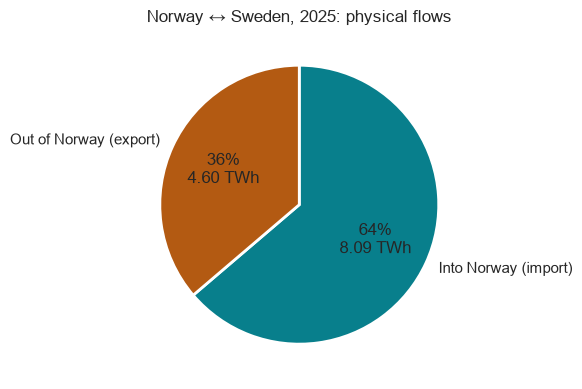

Net export: -3.49 TWh


In [23]:
CHOSEN_NEIGHBOUR = 'Sweden'  # one of LINKS['neighbour']
CHOSEN_YEAR = 2025

year_data = hourly_pdf.loc[(hourly_pdf['neighbour'] == CHOSEN_NEIGHBOUR) & (hourly_pdf['year'] == CHOSEN_YEAR)]
totals = year_data.groupby('direction')['energy_mwh'].sum().reindex(['import', 'export']) / 1e6  # TWh

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.pie(totals, labels=['Into Norway (import)', 'Out of Norway (export)'], colors=['#087F8C', '#B35A12'],
       autopct=lambda share: f'{share:.0f}%\n{share * totals.sum() / 100:.2f} TWh',
       startangle=90, counterclock=False, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax.set_title(f'Norway ↔ {CHOSEN_NEIGHBOUR}, {CHOSEN_YEAR}: physical flows')
fig.tight_layout(); plt.show()
print(f'Net export: {totals["export"] - totals["import"]:.2f} TWh')

### 6.2 Line plot: the first month of a year on one connection

One line per link and direction: colour shows the link (Norwegian area–foreign area) and the line style the
direction (solid = import into Norway, dashed = export out of Norway).

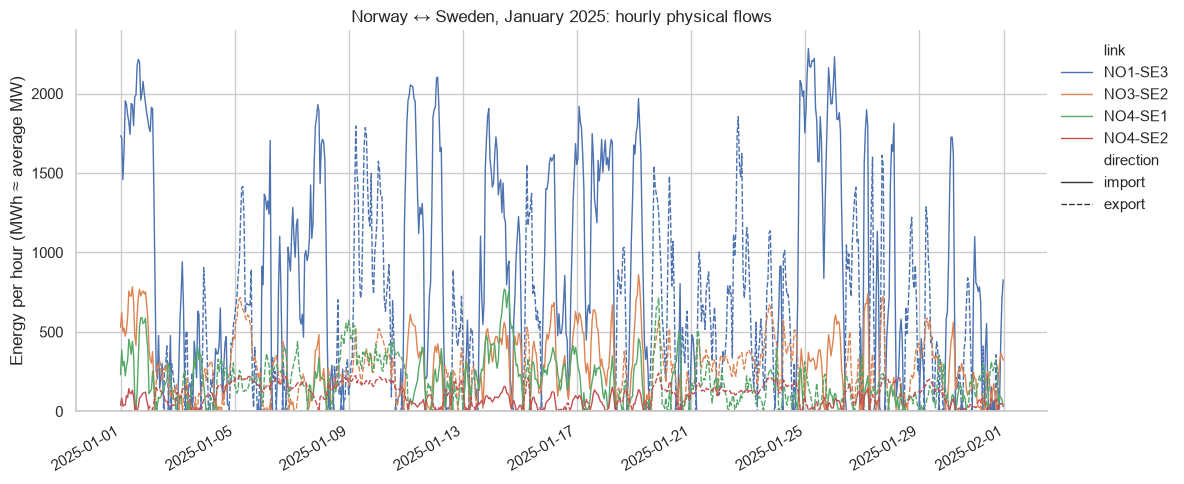

In [24]:
january = hourly_pdf.loc[(hourly_pdf['neighbour'] == CHOSEN_NEIGHBOUR) & (hourly_pdf['year'] == CHOSEN_YEAR)
                         & (hourly_pdf['month'] == 1)].copy()
january['local_time'] = january['time'].dt.tz_convert('Europe/Oslo')

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=january, x='local_time', y='energy_mwh', hue='link', style='direction',
             style_order=['import', 'export'], estimator=None, errorbar=None, linewidth=1, ax=ax)
ax.set(title=f'Norway ↔ {CHOSEN_NEIGHBOUR}, January {CHOSEN_YEAR}: hourly physical flows',
       xlabel='', ylabel='Energy per hour (MWh ≈ average MW)')
ax.set_ylim(bottom=0)
ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), frameon=False)
sns.despine()
fig.autofmt_xdate()
fig.tight_layout(); plt.show()

## 7. Remote database: MongoDB Atlas

### 7.1 Connection and a short data-manipulation test

In [25]:
from pymongo import ASCENDING, MongoClient

client = MongoClient(secrets['mongo']['uri'], serverSelectionTimeoutMS=10_000)
client.admin.command('ping')  # Raises an error if the cluster cannot be reached.
database = client[secrets['mongo'].get('database', 'ind320')]
print('Connected to MongoDB, database:', database.name)

# Insert, update, read and delete in a throw-away collection.
test = database['connection_test']
test.insert_many([{'name': 'NO1', 'note': 'inserted'}, {'name': 'NO2', 'note': 'inserted'}])
test.update_one({'name': 'NO2'}, {'$set': {'note': 'updated'}})
print(list(test.find({}, {'_id': 0})))
test.drop()

Connected to MongoDB, database: ind320
[{'name': 'NO1', 'note': 'inserted'}, {'name': 'NO2', 'note': 'updated'}]


### 7.2 Insert the Spark-extracted data

The app reads the collection `cross_border_flows_hourly`: one document per hour, link and direction. The collection is
dropped and refilled, so running the notebook again does not create duplicates. An index on
(neighbour, year, month) matches the app's queries, so MongoDB does not have to scan every document.

In [26]:
collection = database['cross_border_flows_hourly']

# BSON needs plain Python types: datetime (UTC) for time and int/float for the numbers.
documents = hourly_pdf.assign(time=hourly_pdf['time'].dt.tz_convert('UTC').dt.tz_localize(None))
documents = documents.astype({'year': int, 'month': int, 'energy_mwh': float})
records = documents.to_dict('records')

# Replace the whole collection: drop() removes it in one operation (deleting ~316,000
# documents one by one with delete_many() is slow on the free cluster).
collection.drop()
for first in range(0, len(records), 20_000):  # moderate batches for the free cluster
    collection.insert_many(records[first:first + 20_000], ordered=False)
collection.create_index([('neighbour', ASCENDING), ('year', ASCENDING), ('month', ASCENDING)])
print(f'Documents in MongoDB: {collection.count_documents({}):,}')
print(collection.find_one({}, {'_id': 0}))

Documents in MongoDB: 315,792
{'neighbour': 'Sweden', 'link': 'NO1-SE3', 'from_area': 'NO1', 'to_area': 'SE3', 'direction': 'export', 'time': datetime.datetime(2023, 12, 31, 23, 0), 'energy_mwh': 0.0, 'year': 2024, 'month': 1}


In [27]:
# Check: the same yearly totals computed by MongoDB itself (this is the query behind the app's pie chart).
pipeline = [
    {'$match': {'neighbour': CHOSEN_NEIGHBOUR, 'year': CHOSEN_YEAR}},
    {'$group': {'_id': '$direction', 'twh': {'$sum': '$energy_mwh'}}},
]
for row in collection.aggregate(pipeline):
    print(f"{row['_id']:>6}: {row['twh'] / 1e6:.2f} TWh")

export: 4.60 TWh
import: 8.09 TWh


In [28]:
# Release local resources when the work is done.
spark.stop()
cluster.shutdown()
client.close()

## 8. AI usage

> **TODO (write in your own words before submission).** Facts you can build on: Claude Code (Anthropic) in the Claude
> desktop app was used in Part 2. It read the assignment and my notes, checked the NVE and ENTSO-E API documentation
> and the course book, proposed the project structure, wrote the first version of the Streamlit pages
> (`src/utils/nve_api.py`, `src/utils/flows_db.py`, `src/utils/controls.py`, `src/pages/cross_border.py`), this
> notebook and the `AGENTS.md` rules for AI agents, and
> explained the code. Account registration, passwords, the ENTSO-E token and the MongoDB connection string were
> handled by me and never shared with the AI. Add what *you* checked, changed, asked about and learned.

## 9. Work log

> **TODO (300–500 words, your own experience).** Suggested points: setting up Docker, Cassandra, Java and Spark
> (what worked, what failed), the ENTSO-E account and waiting for the token, what you learned about the NVE time
> columns and areas (Sunday dates, VASS 4 without data), choosing the period and the connection/link
> interpretation, mixed 15/60-minute resolution, MongoDB Atlas and Streamlit secrets, the new app pages, and how
> you checked the results (expected vs. actual).